In [9]:

from pathlib import Path

import numpy as np
import torch

from optimization.generators import generate_problem_data
from optimization.losses import make_quadratic_loss
from optimization.runner import run_optimization
from optimization.optimizers.collinear import CollinearGradients


# конфигурация

N_VALUES = [
    1000, 2000, 3000, 4000, 5000,
    6000, 7000, 8000, 9000, 10000
]

KAPPA_VALUES = [50]
NUM_U0 = 2

NUM_ITERS = 3000
TOL_DIST = 0.05

LR_ADAM = 0.01
LR_NESTEROV = 0.01

BETAS_ADAM = (0.9, 0.999)
MOMENTUM_NESTEROV = 0.9

R = 5.0

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

MAX_ITERS_MAP = {
    "Adam": NUM_ITERS,
    "Метод Нестерова": NUM_ITERS,
    "Метод коллинеарных градиентов": 50,
}

OPTIMIZER_NAMES = [
    "Adam",
    "Метод Нестерова",
    "Метод коллинеарных градиентов",
]


# фиксированные сиды

SEED_A = 1
SEED_B = 2
SEEDS_U0 = [3, 4]


# генерация начальных точек

def generate_initial_point(u_star, n, seed, R=5.0):
    """Генерирует начальную точку на расстоянии R от оптимума."""

    rng = np.random.default_rng(seed)

    direction = rng.standard_normal(n)
    direction = direction / np.linalg.norm(direction)

    u0 = u_star + direction * R

    return u0


# оптимизаторы

def make_optimizers(loss_fn):
    return {
        "Adam": (
            torch.optim.Adam,
            dict(
                lr=LR_ADAM,
                betas=BETAS_ADAM,
            )
        ),

        # Nesterov = SGD с momentum и nesterov=True
        "Метод Нестерова": (
            torch.optim.SGD,
            dict(
                lr=LR_NESTEROV,
                momentum=MOMENTUM_NESTEROV,
                nesterov=True,
            )
        ),

        "Метод коллинеарных градиентов": (
            CollinearGradients,
            dict(
                lr=1.0,
                objective_fn=loss_fn,
                c1=1e-10,
                c2=4.0,
                delta0=1e-9,
                h0=1e-8,
            )
        ),
    }


# эксперимент

def run_experiment():

    results = {
        kappa: {
            u0_idx: {
                n: {}
                for n in N_VALUES
            }
            for u0_idx in range(NUM_U0)
        }
        for kappa in KAPPA_VALUES
    }

    for kappa in KAPPA_VALUES:

        print(
            f"\n==================== κ = {kappa} "
            f"===================="
        )

        for n in N_VALUES:

            # Генерируем A, b и оптимум один раз
            data = generate_problem_data(
                n=n,
                kappa=float(kappa),
                seed_A=SEED_A,
                seed_b=SEED_B,
                seed_u0=SEEDS_U0[0],
                R=R,
            )

            loss_fn = make_quadratic_loss(
                data["A"],
                data["b"],
            )

            optimizers = make_optimizers(loss_fn)

            # Две начальные точки
            initial_points = [
                data["u0"],
                generate_initial_point(
                    u_star=data["u_star"],
                    n=n,
                    seed=SEEDS_U0[1],
                    R=R,
                ),
            ]

            for u0_idx, u0 in enumerate(initial_points):

                for name, (opt_class, opt_kwargs) in optimizers.items():

                    u_final, hist = run_optimization(
                        opt_class,
                        u0_np=u0,
                        loss_fn=loss_fn,
                        u_star_np=data["u_star"],
                        num_iters=MAX_ITERS_MAP[name],
                        tol_dist=TOL_DIST,
                        **opt_kwargs,
                    )

                    f_evals = hist["f_evals"]
                    grad_evals = hist["grad_evals"]

                    results[kappa][u0_idx][n][name] = {
                        "iters": hist["iters"],
                        "f_evals": f_evals,
                        "grad_evals": grad_evals,
                        "total_evals": f_evals + grad_evals,
                    }

            # Лог результатов для обеих начальных точек
            print(f"\n  n = {n}")

            for u0_idx in range(NUM_U0):

                parts = []

                for name in OPTIMIZER_NAMES:

                    r = results[kappa][u0_idx][n][name]

                    parts.append(
                        f"{name}: "
                        f"{r['total_evals']} вычислений "
                        f"({r['iters']} итераций)"
                    )

                print(
                    f"    u0#{u0_idx + 1}: "
                    + " | ".join(parts)
                )

    return results


# запуск

results = run_experiment()


==================== κ = 50 ====================

  n = 1000
    u0#1: Adam: 228 вычислений (114 итераций) | Метод Нестерова: 50 вычислений (25 итераций) | Метод коллинеарных градиентов: 68 вычислений (4 итераций)
    u0#2: Adam: 236 вычислений (118 итераций) | Метод Нестерова: 48 вычислений (24 итераций) | Метод коллинеарных градиентов: 68 вычислений (4 итераций)

  n = 2000
    u0#1: Adam: 174 вычислений (87 итераций) | Метод Нестерова: 52 вычислений (26 итераций) | Метод коллинеарных градиентов: 68 вычислений (4 итераций)
    u0#2: Adam: 182 вычислений (91 итераций) | Метод Нестерова: 50 вычислений (25 итераций) | Метод коллинеарных градиентов: 68 вычислений (4 итераций)

  n = 3000
    u0#1: Adam: 160 вычислений (80 итераций) | Метод Нестерова: 48 вычислений (24 итераций) | Метод коллинеарных градиентов: 68 вычислений (4 итераций)
    u0#2: Adam: 168 вычислений (84 итераций) | Метод Нестерова: 52 вычислений (26 итераций) | Метод коллинеарных градиентов: 68 вычислений (4 итераций)


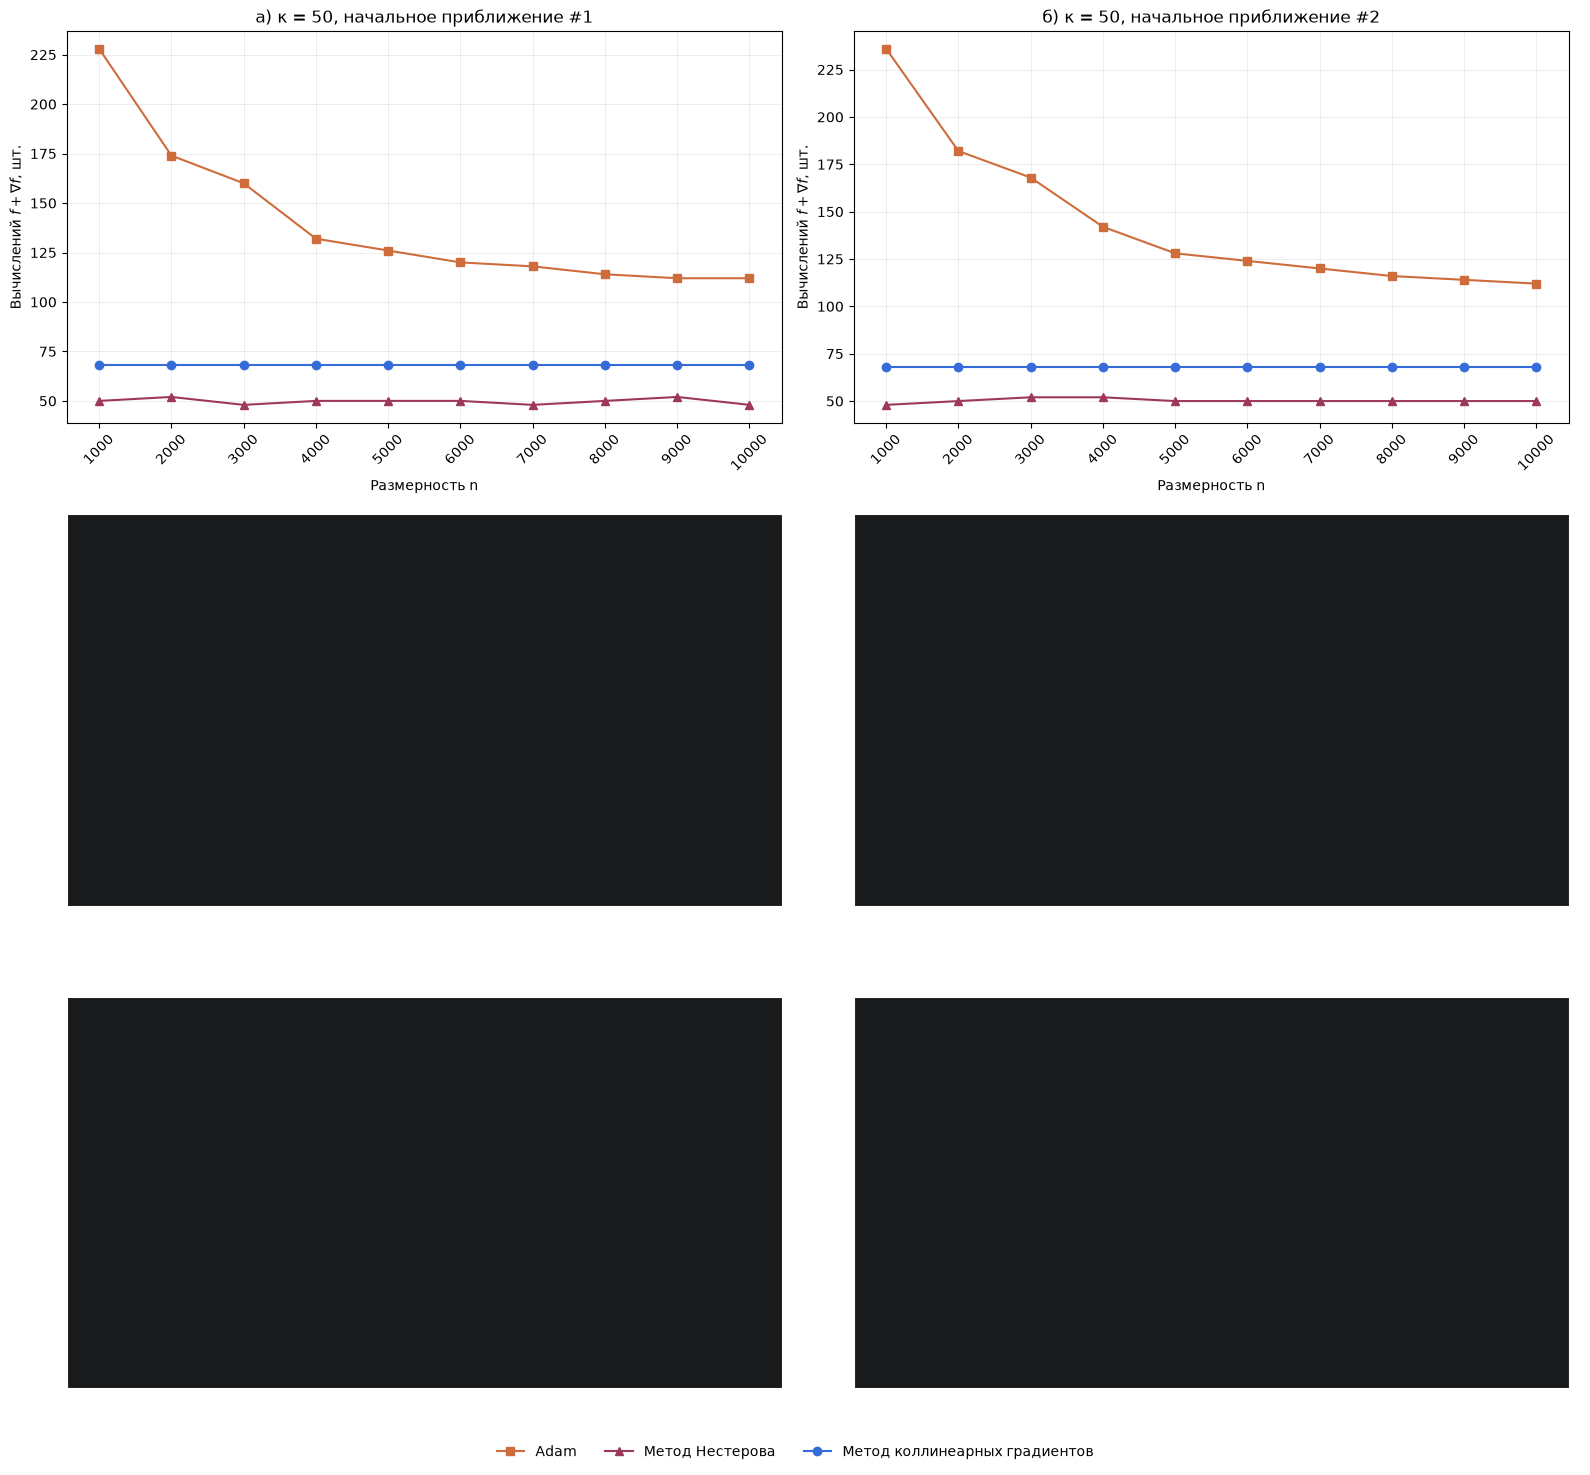

Сохранено: C:\Users\Mikhail\repos\Optimization\experiments\results\comparison_evals_2x3.png


In [10]:

# графики

import matplotlib.pyplot as plt

COLORS = {
    "Adam": "C1",
    "Метод Нестерова": "C2",
    "Метод коллинеарных градиентов": "C0",
}

MARKERS = {
    "Adam": "s",
    "Метод Нестерова": "^",
    "Метод коллинеарных градиентов": "o",
}

# Обозначения графиков
PLOT_LABELS = ["а)", "б)", "в)", "г)", "д)", "е)"]

# Обусловленности для построения графиков
PLOT_KAPPA_VALUES = [50]

# Начальные приближения
PLOT_U0_VALUES = [0, 1]

# Размерности для построения графиков
PLOT_N_VALUES = [
    1000, 2000, 3000, 4000, 5000,
    6000, 7000, 8000, 9000, 10000
]

# Построение графиков
fig, axes = plt.subplots(
    3, 2,
    figsize=(16, 15),
    facecolor="white"
)

# Общая легенда
legend_handles = []

for name in OPTIMIZER_NAMES:
    line, = axes[0, 0].plot(
        [],
        [],
        marker=MARKERS[name],
        color=COLORS[name],
        label=name
    )
    legend_handles.append(line)

# Построение графиков
for row_idx, kappa in enumerate(PLOT_KAPPA_VALUES):

    for col_idx, u0_idx in enumerate(PLOT_U0_VALUES):

        ax = axes[row_idx, col_idx]

        for name in OPTIMIZER_NAMES:

            evals = [
                results[kappa][u0_idx][n][name]["total_evals"]
                for n in PLOT_N_VALUES
            ]

            ax.plot(
                PLOT_N_VALUES,
                evals,
                marker=MARKERS[name],
                color=COLORS[name],
                label=name
            )

        # Оформление
        ax.set_facecolor("white")
        ax.tick_params(colors="black")
        ax.xaxis.label.set_color("black")
        ax.yaxis.label.set_color("black")
        ax.title.set_color("black")

        for spine in ax.spines.values():
            spine.set_color("black")

        ax.ticklabel_format(
            style="plain",
            axis="both",
            useOffset=False
        )

        # Заголовок
        plot_idx = row_idx * 2 + col_idx

        ax.set_xlabel("Размерность n")
        ax.set_ylabel(
            r"Вычислений $f + \nabla f$, шт."
        )

        ax.set_title(
            f"{PLOT_LABELS[plot_idx]} "
            f"κ = {kappa}, начальное приближение #{u0_idx + 1}"
        )

        ax.set_xticks(PLOT_N_VALUES)
        ax.tick_params(axis="x", rotation=45)
        ax.grid(True, alpha=0.3)

# Общая легенда
fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.015),
    ncol=3,
    fontsize=10,
    frameon=False,
    labelcolor="black"
)

# Настройка расположения
fig.tight_layout(rect=(0, 0.045, 1, 1))

out_path = RESULTS_DIR / "comparison_evals_2x3.png"

fig.savefig(
    out_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="white"
)

plt.show()

print(f"Сохранено: {out_path.resolve()}")

In [5]:
# вывод данных графиков текстом

print("\n" + "=" * 80)
print("ДАННЫЕ ГРАФИКОВ")
print("=" * 80)

for row_idx, kappa in enumerate(PLOT_KAPPA_VALUES):

    # Левый график: время
    print(f"\n{PLOT_LABELS[row_idx * 2]} Время вычислений при κ = {kappa}")

    for name in OPTIMIZER_NAMES:

        times = [
            results[kappa][0][n][name]["time"]
            for n in PLOT_N_VALUES
        ]

        print(f"\n{name}")
        print(f"Размерность: {PLOT_N_VALUES}")
        print(f"Время, с: {[round(value, 6) for value in times]}")

    # Правый график: количество вычислений
    print(
        f"\n{PLOT_LABELS[row_idx * 2 + 1]} "
        f"Количество вычислений при κ = {kappa}"
    )

    for name in OPTIMIZER_NAMES:

        evals = [
            results[kappa][0][n][name]["total_evals"]
            for n in PLOT_N_VALUES
        ]

        print(f"\n{name}")
        print(f"Размерность: {PLOT_N_VALUES}")
        print(f"Вычисления: {evals}")

print("\n" + "=" * 80)


ДАННЫЕ ГРАФИКОВ

а) Время вычислений при κ = 10

Adam
Размерность: [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]
Время, с: [0.482081, 0.930742, 2.391563, 3.418391, 5.081746, 6.630608, 8.526502, 12.200691, 11.896332, 14.738214]

Метод Нестерова
Размерность: [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]
Время, с: [0.020116, 0.059398, 0.18789, 0.308202, 0.487103, 0.745009, 1.027949, 1.464259, 1.679901, 2.336773]

Метод коллинеарных градиентов
Размерность: [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]
Время, с: [0.008217, 0.022406, 0.062682, 0.115636, 0.183726, 0.280774, 0.409661, 0.556957, 0.615234, 0.817164]

б) Количество вычислений при κ = 10

Adam
Размерность: [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]
Вычисления: [1612, 1130, 1008, 806, 724, 644, 606, 568, 536, 514]

Метод Нестерова
Размерность: [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]
Вычисления: [72, 72, 74, 74, 74, 74, 74, 74, 74, 74]

Метод к